# 23AIML057
# Set B

## Task 1

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Load dataset
df = pd.read_csv('/content/german_credit_data.csv')

# Display dataset
print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape of dataset: (1000, 21)


,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,none,67,none,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,none,22,none,own,1,skilled employee/ official,1,none,yes,bad
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,none,49,none,own,1,unskilled - resident,2,none,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,car,45,none,for free,1,skilled employee/ official,2,none,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,savings agreement/life insurance,53,none,for free,2,skilled employee/ official,2,none,yes,bad


In [3]:
# Separate features and target
X = df.drop('target', axis=1).copy()
y = df['target'].map({'good': 0, 'bad': 1})

# Identify categorical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

# Encode categorical columns
encoder = OrdinalEncoder()
X[categorical_cols] = encoder.fit_transform(X[categorical_cols])

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\nEncoding completed successfully!")
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTarget distribution in training set:")
print(y_train.value_counts())

print("\nTarget distribution in testing set:")
print(y_test.value_counts())

display(X_train.head())


Categorical columns: ['status_account', 'credit_history', 'purpose', 'status_savings', 'years_employment', 'status_and_sex', 'secondary_obligor', 'collateral', 'other_installment_plans', 'housing', 'job', 'telephone', 'is_foreign_worker']

Numerical columns: ['month_duration', 'credit_amount', 'payment_to_income_ratio', 'residence_since', 'age', 'n_credits', 'n_guarantors']

Encoding completed successfully!
Training set shape: (800, 20)
Testing set shape: (200, 20)

Target distribution in training set:
target
0    560
1    240
Name: count, dtype: int64

Target distribution in testing set:
target
0    140
1     60
Name: count, dtype: int64


,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,residence_since,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker
828,1.0,36,3.0,2.0,8335,4.0,3.0,3,3.0,2.0,4,3.0,47,1.0,0.0,1,1.0,1,0.0,1.0
997,3.0,12,3.0,7.0,804,2.0,3.0,4,3.0,2.0,4,2.0,38,1.0,1.0,1,1.0,1,0.0,1.0
148,1.0,36,1.0,5.0,5371,2.0,0.0,3,3.0,1.0,2,0.0,28,1.0,1.0,2,1.0,1,0.0,1.0
735,0.0,36,0.0,3.0,3990,4.0,2.0,3,0.0,2.0,2,3.0,29,0.0,1.0,1,2.0,1,0.0,1.0
130,0.0,48,3.0,1.0,8487,4.0,1.0,1,0.0,2.0,2,2.0,24,1.0,1.0,1,1.0,1,0.0,1.0


## Task 2

In [4]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # Probability of bad (class 1)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Model: RandomForest (200 trees, depth 8)")
print(f"Test accuracy: {accuracy:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")


Model: RandomForest (200 trees, depth 8)
Test accuracy: 0.7550
ROC-AUC: 0.8070


## Task 3

In [5]:
!pip install shap

In [6]:
import shap

# Create TreeExplainer
explainer = shap.TreeExplainer(model)

# Compute SHAP values for the test dataset
shap_values = explainer.shap_values(X_test)

print("SHAP values computed successfully!")


SHAP values computed successfully!


In [7]:
# Class 1 represents bad applicants
class_index = list(model.classes_).index(1)

if isinstance(shap_values, list):
    # Older SHAP versions: list of arrays, one per class
    shap_bad = shap_values[class_index]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Newer SHAP versions: samples, features, classes
    shap_bad = shap_values[:, :, class_index]

else:
    # Binary output represented as a 2D array
    shap_bad = shap_values

print("SHAP matrix shape:", shap_bad.shape)
print("Test dataset shape:", X_test.shape)


SHAP matrix shape: (200, 20)
Test dataset shape: (200, 20)


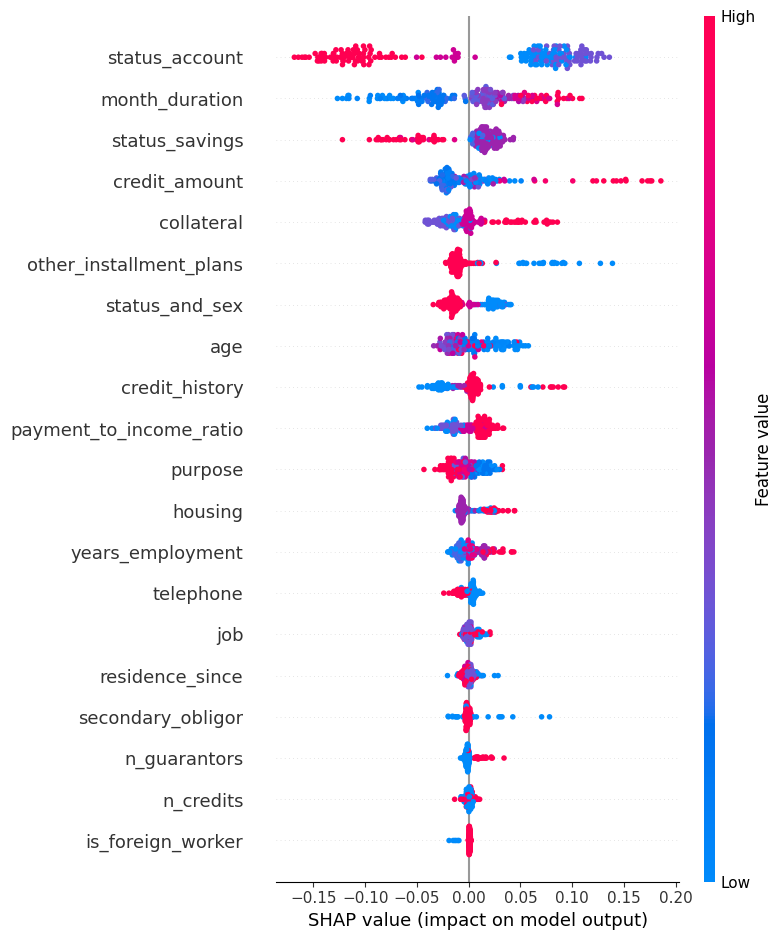

In [8]:
shap.summary_plot(
    shap_bad,
    X_test,
    show=True
)


In [9]:
mean_abs_shap = np.abs(shap_bad).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean |SHAP|': mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by='Mean |SHAP|',
    ascending=False
).reset_index(drop=True)

print("GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print(f"{'RANK':<5} {'FEATURE':<30} {'MEAN|SHAP|':>12}")
print("-" * 50)

for i, row in shap_importance.head(5).iterrows():
    print(f"{i+1:<5} {row['Feature']:<30} {row['Mean |SHAP|']:>12.4f}")

print("-" * 50)


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE                          MEAN|SHAP|
--------------------------------------------------
1     status_account                       0.0931
2     month_duration                       0.0431
3     status_savings                       0.0270
4     credit_amount                        0.0266
5     collateral                           0.0192
--------------------------------------------------


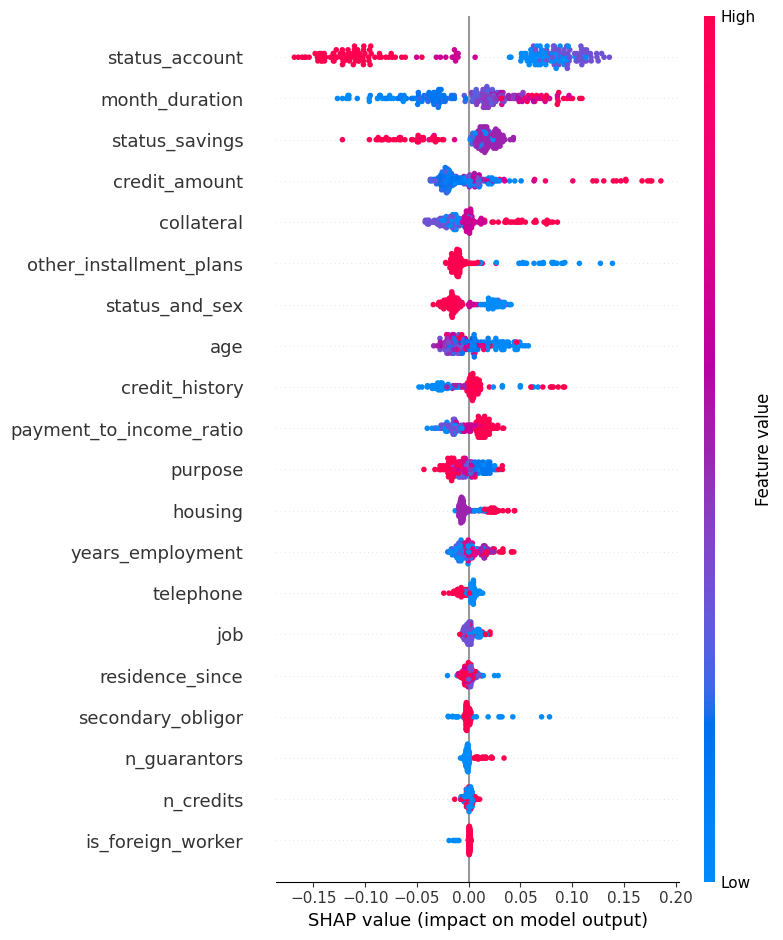

Plot saved : shap_summary.png


In [10]:
import matplotlib.pyplot as plt

plt.figure()

shap.summary_plot(
    shap_bad,
    X_test,
    show=False
)

plt.savefig(
    "shap_summary.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

print("Plot saved : shap_summary.png")


## Task 4

In [11]:
# Identify test applicants predicted as bad
rejected_positions = np.where(y_pred == 1)[0]

if len(rejected_positions) == 0:
    print("No applicants were predicted as bad.")
else:
    # Select the rejected applicant with the highest predicted probability of bad
    selected_pos = rejected_positions[np.argmax(y_prob[rejected_positions])]

    selected_applicant = X_test.iloc[selected_pos]
    selected_probability = y_prob[selected_pos]
    original_index = X_test.index[selected_pos]

    print("Selected applicant's original dataset index:", original_index)
    print("Position within test set:", selected_pos)
    print(f"P(bad): {selected_probability:.4f}")
    print("Prediction: REJECTED")

Selected applicant's original dataset index: 522
Position within test set: 195
P(bad): 0.7520
Prediction: REJECTED


,Encoded feature values
status_account,1.0
month_duration,48.0
credit_history,4.0
purpose,5.0
credit_amount,7119.0
status_savings,2.0
years_employment,0.0
payment_to_income_ratio,3.0
status_and_sex,3.0
secondary_obligor,2.0


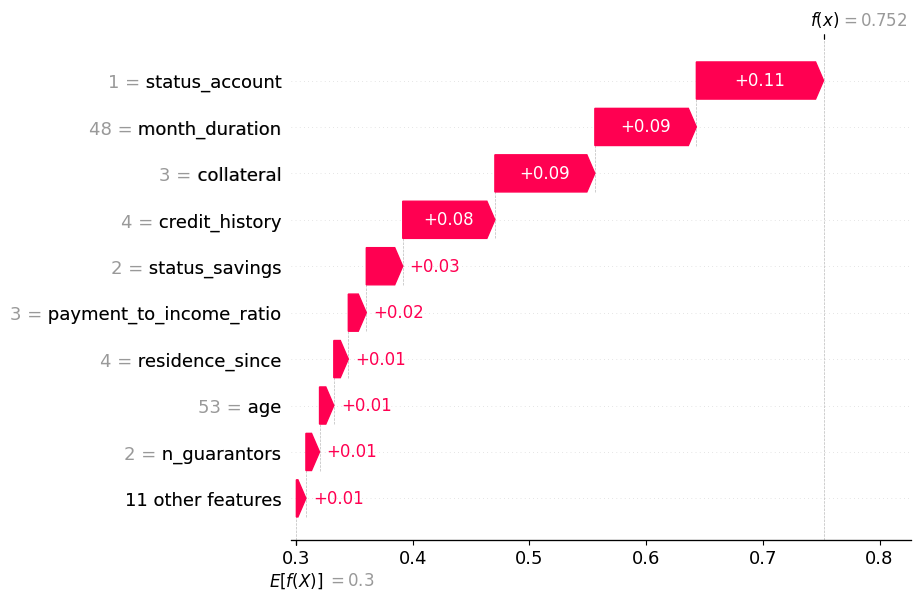

In [12]:
# Get SHAP values for the selected applicant
local_shap = shap_bad[selected_pos]

# Get base value for class 1 (bad)
base_values = explainer.expected_value

if isinstance(base_values, (list, np.ndarray)):
    if np.asarray(base_values).ndim > 0 and len(np.asarray(base_values)) > 1:
        base_value = base_values[class_index]
    else:
        base_value = np.asarray(base_values).flatten()[0]
else:
    base_value = base_values

# Create SHAP Explanation object
local_explanation = shap.Explanation(
    values=local_shap,
    base_values=base_value,
    data=X_test.iloc[selected_pos].values,
    feature_names=X_test.columns.tolist()
)

# Plot waterfall
shap.plots.waterfall(local_explanation, max_display=10)


In [13]:
local_reasons = pd.DataFrame({
    'Feature': X_test.columns,
    'SHAP Value': local_shap,
    'Applicant Encoded Value': X_test.iloc[selected_pos].values
})

# Keep features that positively contribute toward the bad class
positive_reasons = local_reasons[
    local_reasons['SHAP Value'] > 0
].sort_values(by='SHAP Value', ascending=False)

print("TOP 3 SHAP REASONS FOR REJECTION")
print("-" * 65)

display(positive_reasons.head(3))


TOP 3 SHAP REASONS FOR REJECTION
-----------------------------------------------------------------


,Feature,SHAP Value,Applicant Encoded Value
0,status_account,0.109027,1.0
1,month_duration,0.086970,48.0
11,collateral,0.085662,3.0


## Task 5

In [14]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=bea18f931e2a985767a5bdc9308354af905c6b3af919a0616035397209573b4e
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [15]:
from lime.lime_tabular import LimeTabularExplainer

# Map categorical feature indices to their encoded category names
categorical_indices = [
    X.columns.get_loc(col) for col in categorical_cols
]

categorical_names = {}

for col in categorical_cols:
    col_index = X.columns.get_loc(col)
    categories = encoder.categories_[categorical_cols.index(col)]

    categorical_names[col_index] = {
        i: str(category) for i, category in enumerate(categories)
    }

# Initialize LIME
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['good', 'bad'],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode='classification',
    random_state=42
)

print("LIME explainer initialized successfully!")


LIME explainer initialized successfully!


In [16]:
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[selected_pos].values,
    predict_fn=model.predict_proba,
    num_features=5
)

print("LIME explanation for selected applicant:")
print("Prediction: REJECTED")
print(f"P(bad): {selected_probability:.4f}")

print("\nLIME TOP 5 REASONS")
print("-" * 60)

lime_list = lime_exp.as_list(label=1)

for feature, weight in lime_list:
    print(f"{feature:<45} {weight:+.4f}")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


LIME explanation for selected applicant:
Prediction: REJECTED
P(bad): 0.7520

LIME TOP 5 REASONS
------------------------------------------------------------
status_account=< 0 DM                         +0.1241
month_duration > 24.00                        +0.0898
collateral=savings agreement/life insurance   +0.0665
other_installment_plans=none                  -0.0603
credit_amount > 3933.00                       +0.0517


In [19]:
shap_top3 = positive_reasons.head(3)['Feature'].tolist()

# Extract full feature names from LIME rule strings
lime_top3_features = []

for rule, weight in lime_list[:3]:
    matched_feature = next(
        (feature for feature in X.columns if rule.startswith(feature)),
        rule
    )
    lime_top3_features.append(matched_feature)

# Calculate overlap
agreement = len(set(shap_top3) & set(lime_top3_features))

print("SHAP Top 3:", shap_top3)
print("LIME Top 3:", lime_top3_features)
print(f"\nTop-3 agreement: {agreement} / 3")


SHAP Top 3: ['status_account', 'month_duration', 'collateral']
LIME Top 3: ['status_account', 'month_duration', 'collateral']

Top-3 agreement: 3 / 3


## Task 6

In [20]:
sensitive_features = ['age', 'status_and_sex', 'is_foreign_worker']

# Top 3 SHAP reasons
shap_reasons = positive_reasons.head(3)['Feature'].tolist()

# Top 5 LIME reasons
lime_reasons = [
    next((feature for feature in X.columns if rule.startswith(feature)), rule)
    for rule, weight in lime_list[:5]
]

print("SHAP top 3 reasons:", shap_reasons)
print("LIME top 5 reasons:", lime_reasons)

# Check sensitive attributes
sensitive_in_shap = [
    feature for feature in shap_reasons if feature in sensitive_features
]

sensitive_in_lime = [
    feature for feature in lime_reasons if feature in sensitive_features
]

print("\nSensitive attributes in SHAP top 3:", sensitive_in_shap)
print("Sensitive attributes in LIME top 5:", sensitive_in_lime)

if sensitive_in_shap or sensitive_in_lime:
    print("\nSensitive attribute review: REVIEW REQUIRED")
else:
    print("\nSensitive attribute review: No sensitive attributes in these selected reasons")


SHAP top 3 reasons: ['status_account', 'month_duration', 'collateral']
LIME top 5 reasons: ['status_account', 'month_duration', 'collateral', 'other_installment_plans', 'credit_amount']

Sensitive attributes in SHAP top 3: []
Sensitive attributes in LIME top 5: []

Sensitive attribute review: No sensitive attributes in these selected reasons


In [21]:

# Expected Output - Part A: Model and Global Explanation

print("Model : RandomForest (200 trees, depth 8)")
print(f"Test accuracy : {accuracy:.2f}")
print(f"ROC-AUC : {roc_auc:.2f}")

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("RANK FEATURE               MEAN|SHAP|")
print("---------------------------------------")

for i, row in shap_importance.head(5).iterrows():
    print(f"{i+1:>2}    {row['Feature']:<22} {row['Mean |SHAP|']:.3f}")

print("---------------------------------------")
print("Plot saved : shap_summary.png")


Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.76
ROC-AUC : 0.81

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK FEATURE               MEAN|SHAP|
---------------------------------------
 1    status_account         0.093
 2    month_duration         0.043
 3    status_savings         0.027
 4    credit_amount          0.027
 5    collateral             0.019
---------------------------------------
Plot saved : shap_summary.png


In [22]:
# Helper function to convert encoded categorical values to original labels
def get_original_value(feature, encoded_value):
    if feature in categorical_cols:
        col_index = categorical_cols.index(feature)
        categories = encoder.categories_[col_index]
        return categories[int(encoded_value)]
    return encoded_value

# Applicant details
print(f"Applicant (test index {X_test.index[selected_pos]}) : "
      f"P(bad) = {selected_probability:.2f}  ->  REJECTED")

# SHAP top 3 reasons
print("\nSHAP (top 3)")

shap_top3_rows = positive_reasons.head(3)

for _, row in shap_top3_rows.iterrows():
    feature = row['Feature']
    original_value = get_original_value(
        feature,
        X_test.iloc[selected_pos][feature]
    )
    print(f"{feature}={original_value}   {row['SHAP Value']:+.2f}")

# LIME top 5
print("\nLIME (top 5)")

for rule, weight in lime_list[:5]:
    print(f"{rule:<45} {weight:+.2f}")

# Correct feature-name extraction for LIME
lime_top5_features = []

for rule, weight in lime_list[:5]:
    matched_feature = next(
        (feature for feature in X.columns if rule.startswith(feature)),
        rule
    )
    lime_top5_features.append(matched_feature)

# SHAP top 3 feature names
shap_top3_features = shap_top3_rows['Feature'].tolist()

# Top-3 agreement
lime_top3_features = lime_top5_features[:3]
agreement = len(set(shap_top3_features) & set(lime_top3_features))

print("\nTop-3 agreement (SHAP vs LIME) : "
      f"{agreement} / 3")

# Sensitive attribute review
sensitive_features = ['age', 'status_and_sex', 'is_foreign_worker']

sensitive_in_shap = [
    feature for feature in shap_top3_features
    if feature in sensitive_features
]

sensitive_in_lime = [
    feature for feature in lime_top5_features
    if feature in sensitive_features
]

sensitive_found = list(set(sensitive_in_shap + sensitive_in_lime))

# Map dataset column names to exam terminology
sensitive_display = {
    'age': 'age',
    'status_and_sex': 'personal_status',
    'is_foreign_worker': 'foreign_worker'
}

sensitive_display_found = [
    sensitive_display[feature] for feature in sensitive_found
]

print("Sensitive attributes in reasons : "
      + (", ".join(sensitive_display_found) if sensitive_display_found
         else "None"))
if sensitive_found:
    print("Sensitive attribute review : REVIEW")
else:
    print("Sensitive attribute review : No sensitive attributes "
          "in these selected reasons")


Applicant (test index 522) : P(bad) = 0.75  ->  REJECTED

SHAP (top 3)
status_account=< 0 DM   +0.11
month_duration=48.0   +0.09
collateral=savings agreement/life insurance   +0.09

LIME (top 5)
status_account=< 0 DM                         +0.12
month_duration > 24.00                        +0.09
collateral=savings agreement/life insurance   +0.07
other_installment_plans=none                  -0.06
credit_amount > 3933.00                       +0.05

Top-3 agreement (SHAP vs LIME) : 3 / 3
Sensitive attributes in reasons : None
Sensitive attribute review : No sensitive attributes in these selected reasons
